**Question 4**

(a) Noticing that we can write $$\sin(x) = \frac{1}{2i} \left(e^{ix} - e^{-ix} \right)$$
Then the integral can be written as: 
$$
\begin{align*}\int_0^{\infty} k(S(k)-1)\sin(kr)dk &= \int_0^{\infty} k(S(k)-1)\frac{1}{2i} \left(e^{ikr} - e^{-ikr} \right)dk \\ &= \int_0^{\infty} k(S(k)-1)\frac{1}{2i} e^{ikr}dk - \int_0^{\infty} k(S(k)-1)\frac{1}{2i}e^{-ikr}dk \\ \text{Replace } k \rightarrow -k & \text{ on the second term} \\ &= \int_0^{\infty} k(S(k)-1)\frac{1}{2i} e^{ikr}dk - \int_0^{-\infty} (-k)(S(-k)-1)\frac{1}{2i}e^{-i(-k)r}(-dk) \\ \text{Note that } S(k) & \text{ is an even function} \\ \therefore &= \int_0^{\infty} k(S(k)-1)\frac{1}{2i} e^{ikr}dk - \int_0^{-\infty} k(S(k)-1)\frac{1}{2i}e^{ikr}dk \\ &= \int_0^{\infty} k(S(k)-1)\frac{1}{2i} e^{ikr}dk + \int_{-\infty}^0 k(S(k)-1)\frac{1}{2i}e^{ikr}dk \\p(r) &= \int_{-\infty}^{\infty} k(S(k)-1)\frac{1}{2i} e^{ikr}dk 
\end{align*}
$$

(b) Substituting the given parameters, we get: 
$$p(t) = \int_{-\infty}^{\infty} \omega(S(\omega)-1)\frac{1}{2i} e^{i\omega t}d\omega$$
By observation this is in the proportional form of the inverse Fourier transform of $P(\omega)$. i.e.: 
$$p(t) =  \frac{1}{2\pi}\int_{-\infty}^{\infty} P(\omega) e^{i\omega t}d\omega$$
where here the Fourier transform of $p(t)$, is (where $k \rightarrow  \omega$)
$$P(\omega) = \frac{\pi}{i} \omega(S(\omega)-1) = -\pi i \omega(S(\omega)-1)$$

$P(k)$ is a general complex function since $S(k)$ is real. And it is also odd. Since $P(-\omega) = -\pi i (-\omega)(S(-\omega)-1)$, and $S(\omega)$ is even, hence $P(-\omega) = -(-\pi i \omega(S(\omega)-1)) = -P(\omega)$. These imply two things about the original signal $p(r)$:

First because $P(k)$ is odd, this means that its inverse transform: 
$$
\begin{align*}p(-r) &= \frac{1}{2\pi}\int_{-\infty}^{\infty} P(k) e^{-ikr}dk \\ \text{Now changing } & k \rightarrow -k \\  &= \frac{1}{2\pi}\int_{\infty}^{-\infty} P(-k) e^{ikr}(-dk) \\ \text{Since } P(k) &\text{ is odd, and bounds flip} \\ &= -\frac{1}{2\pi}\int_{-\infty}^{\infty} P(k) e^{ikr}(dk) \\ &= -p(r) 
\end{align*}
$$
So the original function $p(r)$ is ALSO odd, if it's Fourier transform $P(k)$ is odd. 

Secondly, because $P(k)$ is a general complex valued function, we can write it like $P(k) = -i \tilde{P}(k)$, and expand the value of $p(r)$ given the facts we have now: 

$$
\begin{align*}p(r) &= \frac{1}{2\pi}\int_{-\infty}^{\infty} P(k) e^{ikr}dk \\ &= \frac{1}{2\pi}\int_{-\infty}^{\infty} -i \tilde{P}(k)(\cos(kr) + i \sin(kr))dk \\ \text{Where } \tilde{P}(k) &= \pi \omega(S(\omega)-1) \text{ is odd}\\ &= \frac{1}{2\pi}\left(\int_{-\infty}^{\infty} \tilde{P}(k) \sin(kr)dk - i \int_{-\infty}^{\infty} \tilde{P}(k) \cos(kr)dk \right) \\ \text{So the imaginary} & \text{ part of the term inside the brackets is} \\ &\Rightarrow -\int_{-\infty}^{\infty} \tilde{P}(k) \cos(kr)dk \\ \text{Because the cosine term is even in } k \text{ but the } &\tilde{P}(k) \text{ term is odd, the integral goes to zero over all space}
\end{align*}
$$
This implies that the function $p(r)$ is REAL, since the imaginary part goes to zero. 

So a complex valued odd function $P(k)$ has inverse Fourier transform that's real valued and odd. We expect this because the parity of the input function determines whether it's a sum of sines or cosines, for a real odd input function we expect it would be a sum of sines, which is the imaginary part of the Fourier transform, but the product must be real, so it must be purely imaginary (also in lecture we were introduced to these results). Now we can plot these results for Argon using the builtin python file.

(c) According to the derivations above, and also the code provided in the documentation, we can write the function RDFcalc. Note that the code given builds Sk with the negative components in physical order (negative on left, positive on right), but we can switch them so it builds it for the inverse transform. Then calculate $P(k)$ using the definition, and inverse transform it to get the integral $p(r)$. Note that by definition the DISCRETE inverse transform has a factor of $1/M$ in front, where $M$ is the length of $P(k)$, and the continuous inverse transform must have a factor of $1/2\pi$ in front. Additionally, the discrete sum is an approximation of the integral by $dk$, so we must multiply it by the weighting of each spacing for the approximation to be accurate. Hence when calculating the inverse of the discrete spctrum, we must multiply it by $M dk /2\pi$ to compare it to the continous. 

(d) Since $g(r)$ is a probability it must have no dimensions, so we can infer that given $P(k)$ has units 1/angstrom, then $p(r)$ must have units 1/angstrom^2. And thus $\rho$ must have units 1/angstrom^3. Then we can input the data given by argon.py to plot the results. 

Since sampling rate in $r$ is given by the relation $2\pi/Ndk$ where $N$ is number of points in $k$. Within the fft, the Nyquist frequency condition (from lecture 6) restricts that the largest frequency that can be resolved is $f = \frac{1}{2dk}$ (needs to be at least two points per cycle). This then becomes 

$$r_{max} = 2\pi f = \frac{\pi}{dk} \approx 26.18 \; \text{Angstroms}$$ 

And as expected, if we increase the limits to around 40, there is some deviations from 1 that start around this value.

(e) From observation of the distribution, there are two peaks. We know that the first peak in $g(r)$ is the most probable separation between first nearest neighbors, and then there's a minimum after the peak, meaning particles are least likely to be found there. Physically we can interpret this as if there are two neighboring atoms in a fluid, the most likely distance they'd be away from eachother is just touching, which separates their molecular centers by roughly $2R_a$ on average if the molecules are treated as hard spheres. So we can simply locate the value of $r$ where $g$ has a maximum, and divide it by two. The value obtained was around $R_a \approx 1.85$ Angstrom which comes pretty close to the theoretical (from Google) of 1.88 Angstrom.

Since ultimately this is not a continuous distribution, but a discrete one on a grid with around $dr = 0.2$ Angstrom. So the uncertainty in this estimation is $\pm 0.1$ Angstrom ($dr/2$), plus the fact that atoms are not generally hard spheres, and the area between the peak and the first minimum is technically all possible places that two adjacent atoms are touching eachother. So we can estimate within an accuracy of around that width.

(f) Here we want to change the sampling range, so this means since the original YanData is sampled at a fixed $dk$, we need to decrease the length of the input. The function we wrote in part b) takes in data $S$, and then forms it's own $Sk$ data by copying $S$ twice for the negative and positive $k$'s. So for a shorter $k_{max}$, we simply have to find how many points of YanData we want to include, with every new $k_{new}$ this is just $N = \lceil k_{new}/dk \rceil$ (take ceiling because when we index the range it's excluding the last index). Then we can iterate this by decreasing the maximum $k$ by 0.1 factor each time (just to see more detail), and find the maximum we can decrease it where we still see two peaks. From the code this is around $k = 3.048 A^{-1}$, which decreased by a factor of $\approx 0.2$

(g) Now we test an increasing sampling rate. This time for every new $dk_{new}$ we test, we need to sample YanData by the same rate (i.e. take every 2 points, every 4 points etc.) as we increase $dk$. After plotting each distribution, by observation the two peaks are just borderline distinguishable after increasing $dk$ by a factor of three. Because the Nyquist limit (from part d)) scales with $dk$, an increase in $dk$ decreases the Nyquist limit. If we wanted to resolve up to the two peaks, then we need the largest $r$ we can trust to be around $r_{max} = \frac{\pi}{dk} \approx 8.5$ Angstrom, which gives us a theoretical $dk_{max} \approx 0.37 A^{-1}$. Clearly this is seen from the results below, where the second peak is almost fading to small wiggles when $dk$ was increased by $3$ times to $\approx 0.36$ (at the border of the analytical Nyquist limit).

AI: Was used to simplify indexing using 'mask' builtin function, to understand 'prominence' and 'distance' parameters in find_peaks. Google was used to understand how to convert mass density to the desired units.

Collaborators: Kieran Phu, Valerie MacIsaac

0.12 128 15.36 15.12


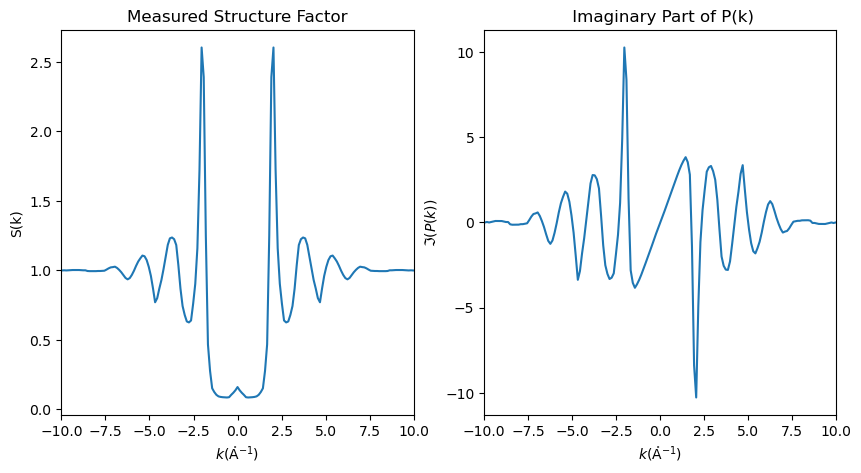

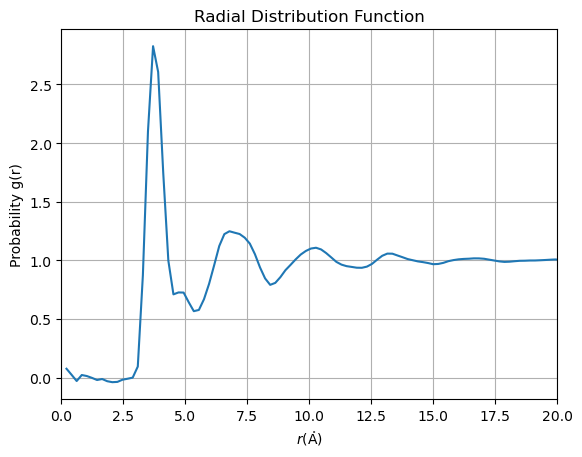

Nyquist limit is r_max = 26.179938779914945
For maximum g(r_max), r_max = 3.6959913571644627
Average molecular radius of Argon R_a  = 1.8479956785822313 Angstorm
Value was obtained on grid with dr = 0.2053328531758035


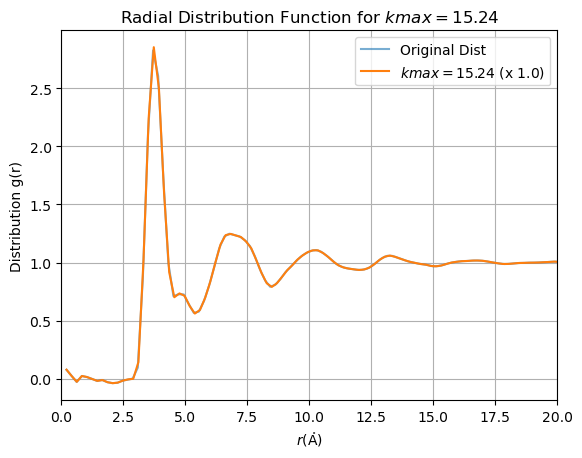

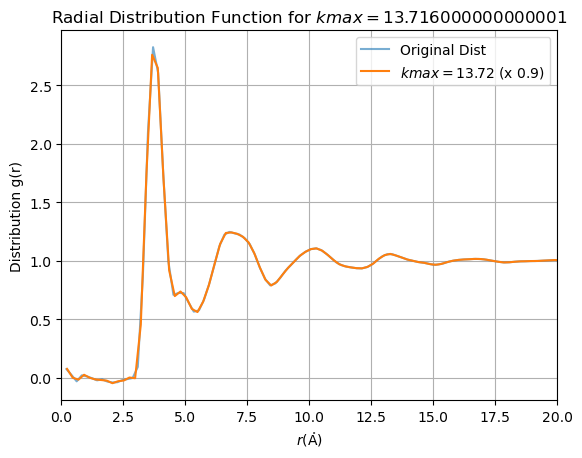

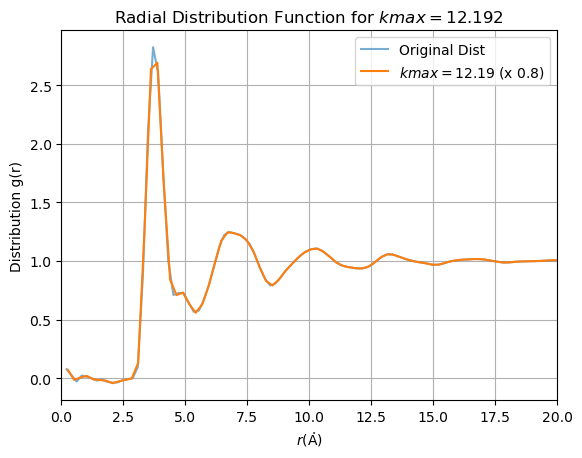

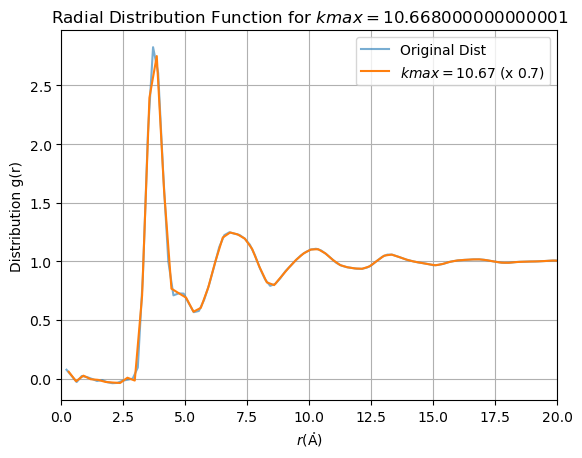

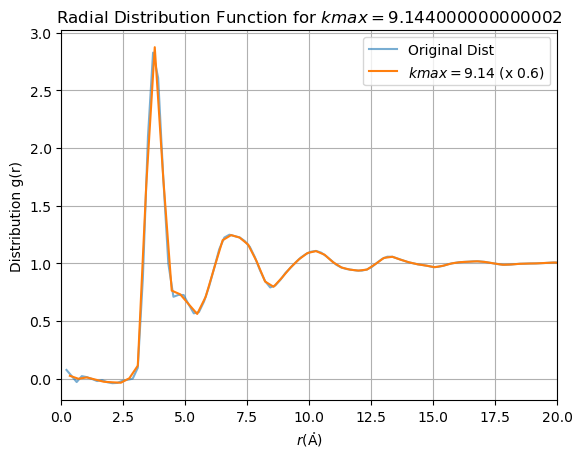

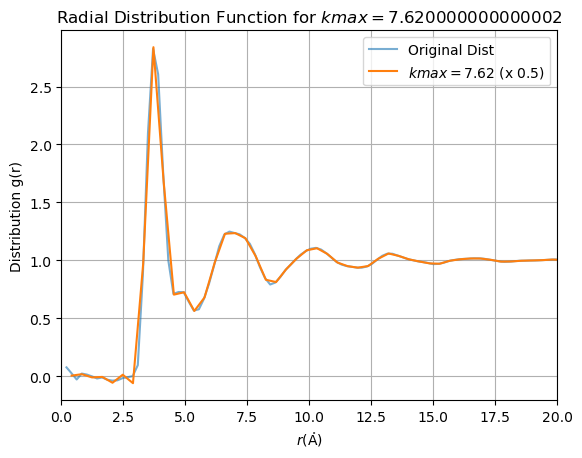

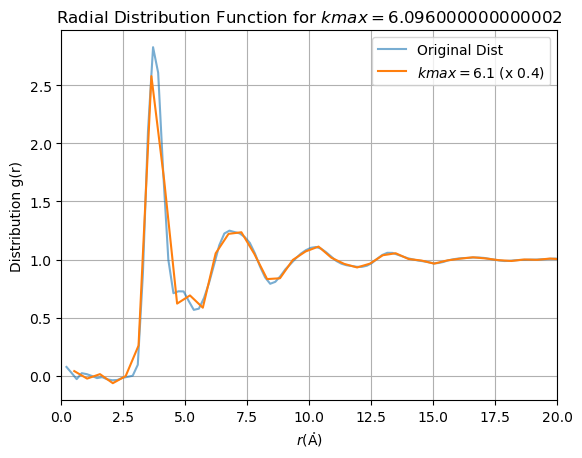

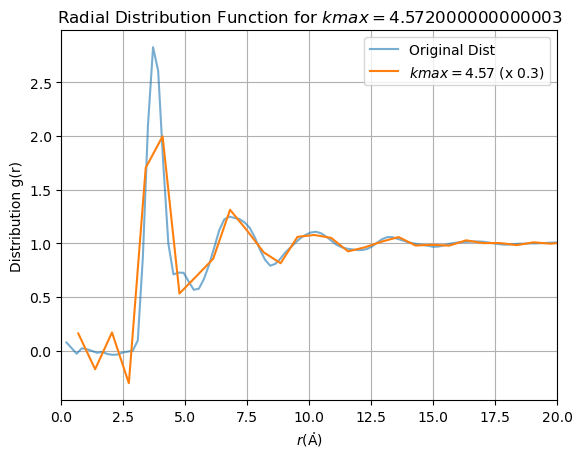

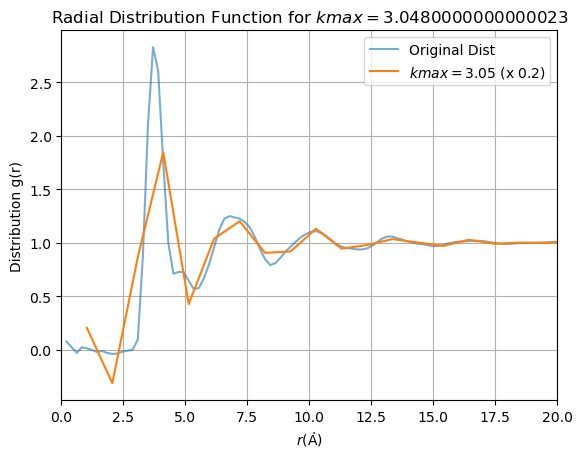

Smallest k_max is 3.0480000000000023, decreased by factor 0.20000000000000015


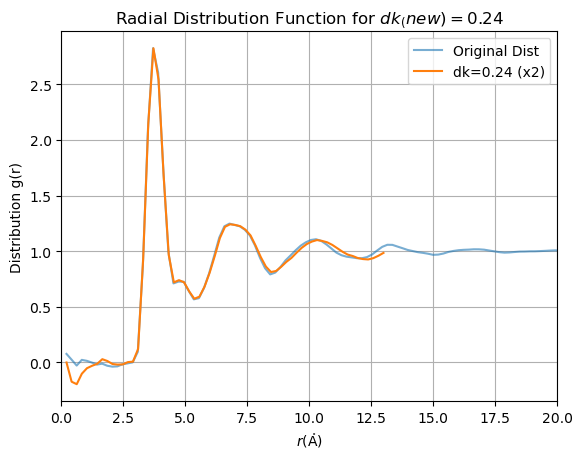

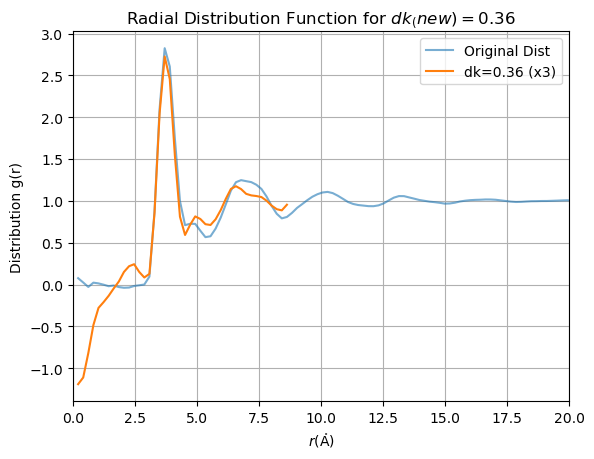

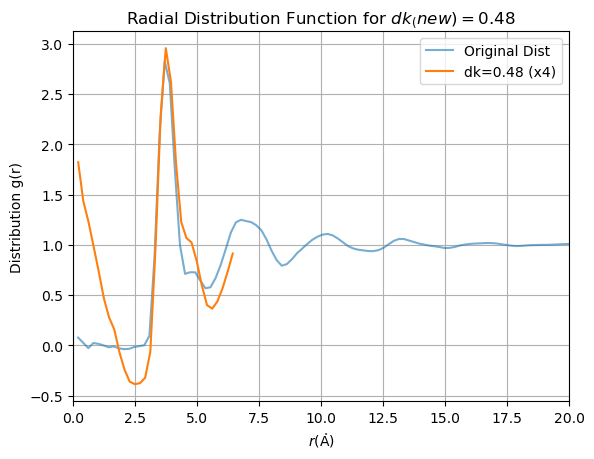

In [344]:
# Question 4: Properties of Argon 

# Import Libraries
import numpy as np 
import matplotlib.pyplot as plt 
import scipy
from scipy.signal import find_peaks
from argon import YanData, dk, massRho, molWeight, Navogadro

# Part b): Plot Argon data
# using the code provided from the assignment documentation 
print (dk , len ( YanData ) , dk * len ( YanData ) , 15 + dk )
N = len ( YanData )
k = np.arange (- N + 1 , N) * dk
Sk = np.empty (( 2 * N - 1 ,) )
Sk [: N] = YanData [: : - 1]
Sk [N:] = YanData [1 :]
Pk = - 1j * np.pi * k * (Sk - 1)

fig , axs = plt.subplots (1 ,2 , figsize = (10,5))
axs[0].plot(k, Sk)
plt.setp(axs[0],xlabel = r"$k(\mathrm{\mathring{A}}^{-1})$ ", 
         ylabel = "S(k)", xlim = [-10,10], title = "Measured Structure Factor")
axs[1].plot(k, np.imag(Pk))
plt.setp(axs[1], xlabel = r"$k(\mathrm{\mathring{A}}^{-1})$" , 
         ylabel = r"$\Im(P(k))$", xlim = [-10,10] , title = " Imaginary Part of P(k)")

plt.show()

# Part c): Write function to calculate Radial Distribution

def RDFcalc(S, dk, rho): 
    """
    Calculates Radial Distribution Function g(r) from given 
    parameters, and outputs the vector g_n and its corresponding radial distance 
    vector r_n
    Inputs: 
    S = Structure factor (intensity)
    dk = Sampling spacing for k (transverse momentum transfer, inverse Angstroms)
    rho = density
    Outputs: 
    Radial distribution vector g_n, radial distance vector r_n
    """
    # We want negative values of S on the second half of the array 
    N = len(S)
    # make the data like from above
    k = np.arange(- N + 1 , N) * dk
    M = len(k)  # amount of k's
    Sk = np.empty ((2 * N - 1 ,) )
    Sk[: N] = S[: : - 1]
    Sk[N:] = S[1 :] # repeat for the negative sides S even
    
    # p(r) is the inverse transform of P(k)
    P_k = - 1j * np.pi * k * (Sk - 1)
    # swap so negative components are at the end
    P_k = scipy.fft.ifftshift(P_k)
    
    # Then do the inverse transform 
    p_r = scipy.fft.ifft(P_k) * (M*dk/(2*np.pi)) # to compare to continuous
    # then shift them back so zero is centered 
    p_r = scipy.fft.fftshift(p_r)
    
    # Then r_n vector is 
    r_n = 2*np.pi*np.fft.fftfreq(M, d=dk) # based on the dk spacing
    # also shift ths so negatives are back on left
    r_n = np.fft.fftshift(r_n) 
    
    # then g(r) is just as equation says, but ensure r is positive and nonzero
    mask = r_n > 0
    r_nn = r_n[mask]
    p_rr = p_r[mask]
    g_n = 1 + 1/(2*np.pi**2*rho*r_nn) *p_rr
    return np.real(g_n), r_nn

# Part d): Calculate g(r) using data provided

# rho is supposed to be units particles/unit volume 
# r here is in A since k is in A^-1, so we need rho to be A^-3
# massRho is in g/cm^3, number of mols / cm^3 is massRho/weight of one mol
no_mols = massRho/molWeight  
N_density = no_mols*Navogadro # number of particles/cm^3
# convert it to angstrom 1cm = 10^8 A
rho_density = N_density/(1e8)**3
g_r, r = RDFcalc(YanData, dk, rho_density)

plt.plot(r, g_r)
plt.title('Radial Distribution Function')
plt.xlim(0, 20)
plt.grid()
plt.xlabel(r"$r (\mathrm{\mathring{A}})$")
plt.ylabel('Probability g(r)')
plt.show()

# How large of r can we trust this

print(f'Nyquist limit is r_max = {np.pi/dk}')

# Part e): Find average molecular radius of liquid argon R_a

# Find the maximum 
maxes, _ = find_peaks(g_r, distance = 2, prominence=0.15)
max_id = maxes[0]
r_max = r[max_id]
print(f'For maximum g(r_max), r_max = {r_max}')
R_a = r_max/2

print(f"Average molecular radius of Argon R_a  = {R_a} Angstorm")
print(f'Value was obtained on grid with dr = {r[1] - r[0]}')

# Part f): Testing shorter sampling range

k_max = 15.24 # A^-1 original k_max
factor = 1.0

while True: 
    # since S is only positive components and we copy it to reflect it, 
    # just shrink YanData to the desired size
    k_new = k_max * factor
    N_new = int(np.ceil(k_new/dk)) # how many new points we wanna take, just take the ceiling
    S_new = YanData[:N_new] 
    
    g_new, r_new = RDFcalc(S_new, dk, rho_density)
    max_new, _ = find_peaks(g_new, distance = 3,height=1.3, prominence = 0.5)
    
    # stop loop if the maximum reached, print the previous value 
    if len(max_new) < 1: 
        print(f'Smallest k_max is {k_max*(factor + 0.1)}, decreased by factor {factor + 0.1}')
        break
    
    # for each decrease, plot it 
    plt.plot(r, g_r, alpha = 0.6, label = 'Original Dist')
    plt.plot(r_new, g_new, label = fr'$kmax = {round(k_new,2)}$ (x {round(factor,1)})')
    plt.title(fr'Radial Distribution Function for $kmax = {k_new}$')
    plt.xlim(0, 20)
    plt.legend()
    plt.grid()
    plt.xlabel(r"$r (\mathrm{\mathring{A}})$")
    plt.ylabel('Distribution g(r)')
    plt.show()
    

    factor -= 0.1

# Part e): Testing larger sampling rate 

for fact in [2, 3, 4]: # try increasing factor by 1 each time
    S_nu = YanData[::fact] # skip to take every factor data point
    dk_nu = dk * fact
    g_nu, r_nu = RDFcalc(S_nu, dk_nu, rho_density)

    plt.plot(r, g_r, alpha = 0.6, label = 'Original Dist')
    plt.plot(r_nu, np.real(g_nu), label=f"dk={dk_nu} (x{fact})")
    plt.title(fr'Radial Distribution Function for $dk_(new) = {dk_nu}$')
    plt.xlim(0, 20)
    plt.legend()
    plt.grid()
    plt.xlabel(r"$r (\mathrm{\mathring{A}})$")
    plt.ylabel('Distribution g(r)')
    plt.show()